# MP3: VideoRAG

## Overview

Video is one of the most common ways people learn, yet finding one specific answer inside a long video is slow. Video platforms and AI assistants now let users ask questions about a video, jump to the moment that answers them, and read automatically generated chapters and summaries. These features rely on video retrieval-augmented generation (VideoRAG): the video is converted into text with timestamps, the text is indexed, and a language model answers each question from the retrieved moments.

In this assignment, you will build and evaluate a VideoRAG system for one YouTube video. You will start from the RAG pipeline you built in MP2 (Pyserini BM25 and Ollama) and extend it with the parts that are specific to video: transcription with timestamps, text for what is shown on screen, questions that refer to a time, and summaries of the whole video.

## Learning Objectives

By completing this assignment, you will:

1. Understand how a VideoRAG system turns a video into searchable text with timestamps.
2. Gain experience using a multimodal model API to transcribe a video and describe what is shown on screen.
3. Learn why questions about a specific time or about the whole video need more than standard retrieval.
4. Learn to evaluate a RAG system by checking retrieval and answers separately.

## Structure

| Part | Goal | Code you write |
|---|---|---|
| 0 | Watch the video and write 5 questions | None |
| 1 | Transcribe the video, run a baseline VideoRAG, and judge its answers | 1 function and 5 judgments |
| 2 | Add what is shown on screen | 2 functions |
| 3 | Route time questions and summary questions | 6 functions |
| 4 | Evaluate the system | 5 verdicts and short answers |

Complete the parts in order. The progress check cells report whether your code runs as expected; they are not used for grading.

## Setup

You installed Pyserini (with Java 21), Ollama, and LangGraph for MP1 and MP2. You also need:

1. `pip install google-genai requests pandas`
2. A free Gemini API key from https://aistudio.google.com/apikey, stored in the environment variable `GEMINI_API_KEY`. Set it in your terminal before you start Jupyter, or run `os.environ["GEMINI_API_KEY"] = "..."` in a separate cell and delete that cell before you submit.
3. Ollama running (`ollama serve`) with the text model you used in MP2.

The notebook reads the video from its YouTube link; nothing is downloaded. Gemini can read public videos only, and the free tier allows 8 hours of YouTube video per day. Each Gemini result is saved, so each step calls the API once.

Run the next three cells.

In [1]:
# Settings
VIDEO_URL       = "https://www.youtube.com/watch?v=OPTKlycwIkM"   # public YouTube video provided by course staff
TRANSCRIPT_PATH = "mp3_transcript.json"   # your transcript from Part 1.1 is saved here
CLIP_PREFIX     = "mp3"                   # prefix for clip ids
WORK_DIR        = "mp3_work"              # saved results and indexes

CLIP_SECONDS    = 30    # length of one clip; each clip is one document
TOP_K           = 3     # clips retrieved per question
TIME_TOLERANCE  = 10    # seconds of slack when checking whether a clip contains an answer's time

OLLAMA_URL      = "http://localhost:11434"
TEXT_MODEL      = "llama3.2"           # the text model you used in MP2
GEMINI_MODEL    = "gemini-3.6-flash"   # current model names: https://ai.google.dev/gemini-api/docs/models

In [2]:
# Helper functions used throughout the notebook. You do not need to change this cell.
import os, re, json, time, math, base64, shutil, subprocess, sys
from typing import Dict, List, Optional, TypedDict

import requests
import pandas as pd
from IPython.display import YouTubeVideo, Markdown, display

os.makedirs(WORK_DIR, exist_ok=True)
COST_PATH = os.path.join(WORK_DIR, "cost.json")
COST = {}
if os.path.exists(COST_PATH):
    with open(COST_PATH) as f:
        COST = json.load(f)

def record_cost(step, seconds, tokens=None):
    """Remember how long a one time step took, and how many video tokens Gemini read (Part 4.4)."""
    COST[step] = {"seconds": round(seconds, 1), "Gemini tokens": tokens}
    with open(COST_PATH, "w") as f:
        json.dump(COST, f, indent=1)

def fmt_time(sec):
    """95 gives '1:35'; 3725 gives '1:02:05'."""
    sec = int(round(sec))
    h, m, s = sec // 3600, sec % 3600 // 60, sec % 60
    return f"{h}:{m:02d}:{s:02d}" if h else f"{m}:{s:02d}"

def parse_time(text):
    """'1:35' gives 95.0, '1:02:05' gives 3725.0, '95' gives 95.0. '', 'all', and None give None."""
    if text is None:
        return None
    text = str(text).strip().lower()
    if text in ("", "all", "none", "n/a"):
        return None
    try:
        nums = [float(p) for p in text.split(":")]
    except ValueError:
        return None
    sec = 0.0
    for n in nums:
        sec = sec * 60 + n
    return sec

def time_link(sec):
    """The time as text, plus a YouTube link that jumps there if VIDEO_URL is set."""
    if not VIDEO_URL:
        return fmt_time(sec)
    sep = "&" if "?" in VIDEO_URL else "?"
    return f"{fmt_time(sec)} {VIDEO_URL}{sep}t={int(sec)}s"

def approx_tokens(text):
    """Rough token count (about 4 characters per token)."""
    return len(text) // 4

def ollama_chat(prompt, model=None, system=None, num_ctx=None, temperature=0):
    """Send one message to Ollama and return the reply text.
    num_ctx: context size in tokens. Raise it for long inputs, or Ollama quietly cuts them off."""
    messages = [{"role": "system", "content": system}] if system else []
    messages.append({"role": "user", "content": prompt})
    options = {"temperature": temperature}
    if num_ctx:
        options["num_ctx"] = num_ctx
    model = model or TEXT_MODEL
    try:
        r = requests.post(f"{OLLAMA_URL}/api/chat", timeout=900,
                          json={"model": model, "messages": messages, "stream": False, "options": options})
    except requests.ConnectionError:
        raise RuntimeError("Can't reach Ollama. Start it with `ollama serve`.")
    if r.status_code != 200:
        raise RuntimeError(f"Ollama error {r.status_code}: {r.text[:200]} (did you run `ollama pull {model}`?)")
    text = r.json()["message"]["content"]
    return re.sub(r"<think>.*?</think>", "", text, flags=re.S).strip()

def youtube_id(url):
    """The 11 character video id inside a YouTube link, or None."""
    m = re.search(r"(?:v=|youtu\.be/|shorts/|embed/)([A-Za-z0-9_-]{11})", url or "")
    return m.group(1) if m else None

def parse_json(text):
    """Read JSON from a model reply, ignoring code fences or extra words around it."""
    text = re.sub(r"^```(?:json)?\s*|\s*```$", "", text.strip())
    try:
        return json.loads(text)
    except json.JSONDecodeError:
        m = re.search(r"\[.*\]|\{.*\}", text, re.S)
        if m:
            return json.loads(m.group(0))
        raise

def gemini_video(prompt, step="Gemini call", json_output=False, high_res=False):
    """Send the YouTube video (by its link) and a prompt to Gemini, and return the reply text.
    Gemini looks at about 1 frame per second and hears the audio.
    json_output: ask for JSON only.  high_res: read small on screen text better, for about 3 times the tokens.
    step: a name for this call in the Part 4.4 cost table."""
    from google import genai
    from google.genai import types, errors
    settings = {"temperature": 0}
    if json_output:
        settings["response_mime_type"] = "application/json"
    if high_res:
        settings["media_resolution"] = types.MediaResolution.MEDIA_RESOLUTION_HIGH
    contents = types.Content(role="user", parts=[types.Part(file_data=types.FileData(file_uri=VIDEO_URL)),
                                                 types.Part(text=prompt)])
    client = genai.Client()   # reads GEMINI_API_KEY from the environment
    for attempt in range(4):
        try:
            t0, text, tokens = time.time(), "", None
            for chunk in client.models.generate_content_stream(
                    model=GEMINI_MODEL, contents=contents, config=types.GenerateContentConfig(**settings)):
                text += chunk.text or ""
                if chunk.usage_metadata and chunk.usage_metadata.prompt_token_count:
                    tokens = chunk.usage_metadata.prompt_token_count
            record_cost(step, time.time() - t0, tokens)
            return text
        except errors.APIError as e:
            if e.code in (429, 500, 503) and attempt < 3:
                print(f"Gemini is busy ({e.code}); trying again in 30 s...")
                time.sleep(30)
            else:
                raise

print("Helpers ready.")

Helpers ready.


In [3]:
# Environment check. Fix any item marked FIX, then run this cell again.
def setup_check():
    all_good = True
    def report(name, good, tip=""):
        nonlocal all_good
        all_good = all_good and good
        print(("pass  " if good else "FIX   ") + name + ("" if good else f"   ({tip})"))

    report("VIDEO_URL is a YouTube link", youtube_id(VIDEO_URL) is not None, "set VIDEO_URL to a public YouTube video")
    if os.path.exists(TRANSCRIPT_PATH):
        report("saved transcript found", True)
    for module, tip in [("google.genai", "pip install google-genai"), ("pyserini", "same setup as MP1/MP2"),
                        ("langgraph", "same setup as MP2")]:
        try:
            __import__(module)
            report(f"{module} installed", True)
        except ImportError:
            report(f"{module} installed", False, tip)
    report("GEMINI_API_KEY set", bool(os.environ.get("GEMINI_API_KEY") or os.environ.get("GOOGLE_API_KEY")),
           "get a free key at https://aistudio.google.com/apikey, see Setup")
    try:
        names = [m["name"] for m in requests.get(f"{OLLAMA_URL}/api/tags", timeout=10).json()["models"]]
        report("Ollama running", True)
        have = TEXT_MODEL in names or (":" not in TEXT_MODEL and TEXT_MODEL + ":latest" in names)
        report(f"Ollama model {TEXT_MODEL} pulled", have, f"ollama pull {TEXT_MODEL}")
    except Exception:
        report("Ollama running", False, "start it with `ollama serve`")
    print("\nAll set." if all_good else "\nFix the items above, then run this cell again.")

setup_check()

pass  VIDEO_URL is a YouTube link
pass  saved transcript found
pass  google.genai installed
pass  pyserini installed
pass  langgraph installed
pass  GEMINI_API_KEY set
pass  Ollama running
pass  Ollama model llama3.2 pulled

All set.


---
## Part 0: Watch the Video and Write Your Questions

### Goal
Create a small test set of natural questions before you see what the system can do.

### Steps
1. Watch the whole video.
2. Write 5 questions you would naturally ask about it. For each question, write your own answer and the time where the answer appears (`"m:ss"`), or `"all"` if the answer requires the whole video.
3. Do not change your questions after this part, and do not read the course questions in Part 4 until you finish it.

Watch the video here: [https://www.youtube.com/watch?v=OPTKlycwIkM](https://www.youtube.com/watch?v=OPTKlycwIkM)

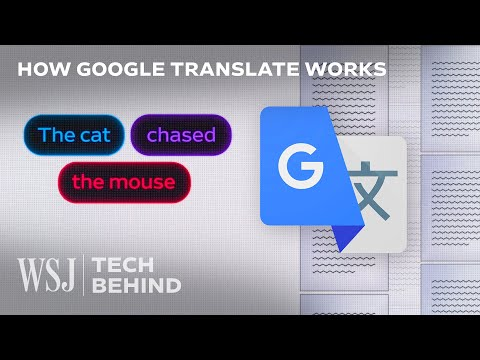

In [4]:
display(Markdown(f"Watch the video here: [{VIDEO_URL}]({VIDEO_URL})"))
display(YouTubeVideo(youtube_id(VIDEO_URL), width=640, height=360))   # may not load in VS Code (Error 153); use the link

In [5]:
# Write 5 questions. time: where the answer appears, as "m:ss", or "all" if it requires the whole video.
MY_QUESTIONS = [
    {"q": "To perform the translation, how many examples are used during the machine learning?", "my_answer": "billions", "time": "1:52"},
    {"q": "What is a context vector?", "my_answer": "A list of numbers which represent what the sentence means", "time": "3:05"},
    {"q": "Is it possible to test every potential translation circumstance?", "my_answer": "not possible", "time": "4:18"},
    {"q": "How does Optical character recognition use transformers?", "my_answer": "First, identifies lines of text and text direction. Then devides image into tokens.", "time": "5:24"},
    {"q": "What are the difficulties with Optical character recognition?", "my_answer": "deformed text", "time": "7:25"},
]
def transcribe_video():
    # == Gemini Transcription == #
    prompt = (
        "Transcribe all speech in this video, word for word, in order. "
        "Split it into short pieces of one sentence or phrase each, never longer than 15 seconds. "
        'Return a JSON list where each item is {"start": "m:ss", "end": "m:ss", "text": "..."}. '
        "Use the times at which the words are actually spoken. "
        "Do not summarize, and do not describe the visuals. Return only the JSON."
    )
    reply = gemini_video(prompt, "transcription", json_output=True)
    data = parse_json(reply)
    return data.get("segments", data) if isinstance(data, dict) else data

In [6]:
MY_FILLED = [m for m in MY_QUESTIONS if m["q"].strip()]
print(f"{len(MY_FILLED)} questions written:", "pass" if len(MY_FILLED) >= 5 else "not pass (write 5 questions)")
for i, m in enumerate(MY_FILLED, 1):
    t = str(m["time"]).strip().lower()
    if not m["my_answer"].strip():
        print(f"  #{i}: add your answer")
    if t != "all" and parse_time(t) is None:
        print(f"  #{i}: time should look like \"1:35\", or \"all\"")

5 questions written: pass


---
## Part 1: Baseline VideoRAG

### Goal
Transcribe the video, apply your MP2 pipeline to the transcript, and judge its answers to your questions.

The baseline works as follows:

video → transcript with timestamps → 30 second clips → BM25 index (as in MP1 and MP2) → Ollama answers from the top clips and cites their times

Each clip is one document. You write the transcription step (1.1); the rest of this part is provided.

### 1.1 Transcript (you write this)
A transcript converts speech into text, with a time on every piece. Every later step depends on these times: clips, cited times, and time questions.

Common ways to get the transcript of a YouTube video:
1. YouTube's built-in transcript (the "Show transcript" button in the video description).
2. A model that reads the video from its link, such as Gemini. Its free tier is the default in this notebook, through `gemini_video`.
3. A speech to text API such as Whisper. These APIs need an audio file, so use them only if you have the right to download the video.

Implement `transcribe_video()` with any free API. The next cell saves your result to `TRANSCRIPT_PATH`, so the API is called once; set `REDO_TRANSCRIPT = True` to call it again.

In [7]:
def transcribe_video():
    # == Gemini Transcription == #
    prompt = (
        "Transcribe all speech in this video, word for word, in order. "
        "Split it into short pieces of one sentence or phrase each, never longer than 15 seconds. "
        'Return a JSON list where each item is {"start": "m:ss", "end": "m:ss", "text": "..."}. '
        "Use the times at which the words are actually spoken. "
        "Do not summarize, and do not describe the visuals. Return only the JSON."
    )
    reply = gemini_video(prompt, "transcription", json_output=True)
    data = parse_json(reply)
    return data.get("segments", data) if isinstance(data, dict) else data

In [8]:
REDO_TRANSCRIPT = False   # set True to run transcribe_video() again, then back to False

def load_transcript():
    """Run transcribe_video() once and save the result. Later runs read the saved file."""
    if os.path.exists(TRANSCRIPT_PATH) and not REDO_TRANSCRIPT:
        with open(TRANSCRIPT_PATH) as f:
            data = json.load(f)
        print(f"Loaded {TRANSCRIPT_PATH}")
    else:
        COST.pop("transcription", None)
        t0 = time.time()
        data = transcribe_video()
        if "transcription" not in COST:   # gemini_video records its own time and tokens
            record_cost("transcription", time.time() - t0)
    if isinstance(data, str):
        data = parse_json(data)
    segments = data.get("segments", []) if isinstance(data, dict) else data
    pieces = []
    for p in segments:
        text, start = str(p.get("text", "")).strip(), parse_time(p.get("start"))
        if text and start is not None:
            pieces.append({"start": start, "end": max(parse_time(p.get("end")) or start, start), "text": text})
    pieces.sort(key=lambda p: p["start"])
    with open(TRANSCRIPT_PATH, "w") as f:
        json.dump(pieces, f, indent=1)
    return pieces

# Progress check: Part 1.1
try:
    TRANSCRIPT = load_transcript()
    DURATION = max((p["end"] for p in TRANSCRIPT), default=0.0)
    words = sum(len(p["text"].split()) for p in TRANSCRIPT)
    too_long = sum(1 for p in TRANSCRIPT if p["end"] - p["start"] > 2 * CLIP_SECONDS)
    good = len(TRANSCRIPT) >= 5 and words >= 50 and too_long == 0
    print("transcribe_video:", "pass" if good else "not pass (need many short pieces with times; see the docstring)")
    print(f"{len(TRANSCRIPT)} pieces, {words} words, speech ends at {fmt_time(DURATION)}"
          + (f", {too_long} pieces longer than {2 * CLIP_SECONDS} s" if too_long else ""))
    print("The first three:")
    for p in TRANSCRIPT[:3]:
        print(f"  [{fmt_time(p['start'])} to {fmt_time(p['end'])}] {p['text']}")
except NotImplementedError:
    print("transcribe_video: not yet implemented. Finish it before you run the rest of the notebook.")
except Exception as e:
    print(f"transcribe_video: error, {type(e).__name__}: {e}")

Loaded mp3_transcript.json
transcribe_video: pass
83 pieces, 1448 words, speech ends at 8:14
The first three:
  [0:00 to 0:04] In a fraction of a second, Google Translate can make sense of your surroundings.
  [0:04 to 0:09] But this isn't the same Google Translate from the early 2000s.
  [0:09 to 0:13] Over the past two decades, the technology has gone through a complete overhaul,


### 1.2 Clips
The timeline is divided into clips of equal length, and each transcript piece goes into the clip where it starts. Clip ids contain the clip number (for example, `mp3_004`), so each retrieved id maps back to a time.

In [9]:
def make_clips(pieces, duration, clip_seconds=CLIP_SECONDS):
    n = max(1, math.ceil(duration / clip_seconds))
    clips = [{"id": f"{CLIP_PREFIX}_{i:03d}", "index": i, "start": float(i * clip_seconds),
              "end": float(min((i + 1) * clip_seconds, duration)), "transcript": ""} for i in range(n)]
    for p in pieces:
        c = clips[min(int(p["start"] // clip_seconds), n - 1)]
        c["transcript"] = (c["transcript"] + " " + p["text"]).strip()
    return clips

CLIPS = make_clips(TRANSCRIPT, DURATION)
print(f"{len(CLIPS)} clips of {CLIP_SECONDS} s")
for c in CLIPS[:3]:
    print(f"  {c['id']}  {fmt_time(c['start'])} to {fmt_time(c['end'])}: {c['transcript'][:90]}")

17 clips of 30 s
  mp3_000  0:00 to 0:30: In a fraction of a second, Google Translate can make sense of your surroundings. But this 
  mp3_001  0:30 to 1:00: There's very little code left today from the early days of of the phrase-based translation
  mp3_002  1:00 to 1:30: It now uses a much more sophisticated machine learning approach, a so-called Transformer m


### 1.3 Index
Each clip is indexed with Pyserini BM25, as in MP1 and MP2: one JSON line per clip with `id` and `contents`. You may replace `search` with your own MP2 retriever.

In [10]:
from pyserini.search.lucene import LuceneSearcher

class ClipIndex:
    """A BM25 index over clips, built with Pyserini as in MP1/MP2.
    text_fn(clip) decides the text of each clip document."""

    def __init__(self, name, clips, text_fn):
        self.name = name
        self.docs = {c["id"]: {**c, "text": text_fn(c)} for c in clips}
        folder = os.path.join(WORK_DIR, f"index_{name}")
        docs_dir, index_dir = os.path.join(folder, "docs"), os.path.join(folder, "index")
        shutil.rmtree(folder, ignore_errors=True)
        os.makedirs(docs_dir)
        with open(os.path.join(docs_dir, "docs.jsonl"), "w") as f:
            for d in self.docs.values():
                f.write(json.dumps({"id": d["id"], "contents": d["text"]}) + "\n")
        t0 = time.time()
        run = subprocess.run(
            [sys.executable, "-m", "pyserini.index.lucene", "--collection", "JsonCollection",
             "--input", docs_dir, "--index", index_dir, "--generator", "DefaultLuceneDocumentGenerator",
             "--threads", "1", "--storePositions", "--storeDocvectors", "--storeRaw"],
            capture_output=True, text=True)
        if run.returncode != 0:
            raise RuntimeError("Indexing failed:\n" + (run.stderr or run.stdout)[-2000:])
        record_cost(f"index ({name})", time.time() - t0)
        self.searcher = LuceneSearcher(index_dir)

    def search(self, query, k=TOP_K):
        """Top k clips for the query, best first, each with its BM25 'score'.
        You may replace this with your MP2 retriever (for example your Task 3 fusion)."""
        hits = self.searcher.search(query, k)
        return [{**self.docs[h.docid], "score": round(float(h.score), 2)} for h in hits]

BASE_INDEX = ClipIndex("transcript", CLIPS, lambda c: c["transcript"])
sample = " ".join(next((c["transcript"] for c in CLIPS if c["transcript"]), "video").split()[:6])
print(f"Indexed {len(CLIPS)} clips. Test search for: {sample!r}")
for c in BASE_INDEX.search(sample, 2):
    print(f"  {c['id']} at {fmt_time(c['start'])}, score {c['score']}: {c['text'][:80]}")

W1127 14:51:04.025000 70874 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Indexed 17 clips. Test search for: 'In a fraction of a second,'
  mp3_000 at 0:00, score 2.62: In a fraction of a second, Google Translate can make sense of your surroundings.


### 1.4 Answer Generation
As in MP2, the retrieved clips are placed in the prompt, and the LLM is asked to answer only from them. Each clip carries its time range, so the answer can point to where in the video the information appears.

In [11]:
ANSWER_SYSTEM = (
    "You answer questions about a video using only the video clips given to you. "
    "Each clip starts with its time range. Cite the time for each fact you use, like [1:30]. "
    "If the clips do not contain the answer, reply exactly: I can't find this in the video. "
    "Be short and factual."
)

def format_clips(clips):
    """Clips as prompt text, each one starting with its time range."""
    return "\n\n".join(f"[{fmt_time(c['start'])} to {fmt_time(c['end'])}]\n{c['text']}" for c in clips)

def answer_from_clips(question, clips):
    """Ask the LLM to answer only from these clips."""
    if not clips:
        return "I can't find this in the video."
    return ollama_chat(f"Video clips:\n\n{format_clips(clips)}\n\nQuestion: {question}",
                       system=ANSWER_SYSTEM, num_ctx=8192)

def rag_answer(question, index, k=TOP_K):
    """MP2 style RAG: retrieve the top k clips, then answer from them."""
    clips = index.search(question, k)
    return {"question": question, "path": "specific", "answer": answer_from_clips(question, clips), "clips": clips}

def moment_found(clips, answer_time):
    """True if a clip covers answer_time (with TIME_TOLERANCE slack). None if there is no single time."""
    t = parse_time(answer_time)
    if t is None:
        return None
    return any(c["start"] - TIME_TOLERANCE <= t < c["end"] + TIME_TOLERANCE for c in clips)

def show(result, mine=None):
    """Print one result. mine: your question from Part 0, to compare with your answer."""
    print(f"Q: {result['question']}   (path: {result.get('path', 'specific')})")
    print(f"A: {result['answer']}")
    clips = result.get("clips", [])
    if clips:
        print("Clips used: " + ", ".join(fmt_time(c["start"]) for c in clips))
        if VIDEO_URL:
            print("Jump to the first clip: " + time_link(clips[0]["start"]))
    if mine:
        found = {True: "yes", False: "no", None: "n/a"}[result.get("moment_found")]
        print(f"Your answer: {mine['my_answer']}   (at {mine['time']}; retrieval found your moment: {found})")
    print("=" * 70)

print("Answer functions ready.")

Answer functions ready.


### 1.5 Ask Your Questions
The first cell below prints the exact clip text the LLM receives for your first question. The second cell runs all your questions. "Retrieval found your moment" checks whether a retrieved clip covers the time you wrote; it evaluates retrieval only. You judge the answers in 1.6.

In [12]:
if MY_FILLED:
    q = MY_FILLED[0]["q"]
    print("Question:", q, "\n")
    print(format_clips(BASE_INDEX.search(q)) or "(no clip shares a word with the question)")

Question: To perform the translation, how many examples are used during the machine learning? 

[1:30 to 2:00]
For instance: king minus man plus woman equals queen. The specific numbers assigned to each word don't really matter, and they're different in different languages. But what matters is how each word relates to every other word. It's all based on machine learning from billions of examples. But most of the time you want to translate something, it's not just an individual word. So the computer also has to figure out how words work together.

[4:30 to 5:00]
For example, if you want to translate something in Japanese to Zulu, it will go from Japanese to English and then English to Zulu. The first thing that happens when you use Google AI Translate is that we have to actually extract the text from the image. And so as you can see here, it detects that now this is Chinese and it translates it to English. It makes information a lot more accessible, because for many people, typing scrip

In [13]:
baseline_results = []
for mine in MY_FILLED:
    r = rag_answer(mine["q"], BASE_INDEX)
    r["moment_found"] = moment_found(r["clips"], mine["time"])
    baseline_results.append(r)
    show(r, mine)

Q: To perform the translation, how many examples are used during the machine learning?   (path: specific)
A: [1:30]
Clips used: 1:30, 4:30, 1:00
Jump to the first clip: 1:30 https://www.youtube.com/watch?v=OPTKlycwIkM&t=90s
Your answer: billions   (at 1:52; retrieval found your moment: yes)
Q: What is a context vector?   (path: specific)
A: A context vector is a list of numbers that represents what a sentence means, not just the sum of its words, if the model has done its job correctly. [3:00 to 3:30]
Clips used: 3:00, 2:30, 1:00
Jump to the first clip: 3:00 https://www.youtube.com/watch?v=OPTKlycwIkM&t=180s
Your answer: A list of numbers which represent what the sentence means   (at 3:05; retrieval found your moment: yes)
Q: Is it possible to test every potential translation circumstance?   (path: specific)
A: I can't find this in the video.
Clips used: 4:00, 0:30, 2:30
Jump to the first clip: 4:00 https://www.youtube.com/watch?v=OPTKlycwIkM&t=240s
Your answer: not possible   (at 4:18

### 1.6 Judge the Answers
Compare each answer with your own. Record a verdict for each question and, for each answer that is not correct, the main cause.

In [14]:
CAUSES = {
    "retrieval":     "the clip with the answer was not retrieved",
    "on_screen":     "the answer is only shown on screen",
    "time":          "the question is about a time in the video",
    "whole_video":   "the question needs the whole video",
    "transcript":    "the transcript has a mistake",
    "hallucination": "the answer adds facts that are not in the clips",
    "other":         "something else (explain in your answer below)",
}
for key, meaning in CAUSES.items():
    print(f"{key:14s} {meaning}")

retrieval      the clip with the answer was not retrieved
on_screen      the answer is only shown on screen
time           the question is about a time in the video
whole_video    the question needs the whole video
transcript     the transcript has a mistake
hallucination  the answer adds facts that are not in the clips
other          something else (explain in your answer below)


In [15]:
BASELINE_JUDGMENTS = [
    {"verdict": "wrong",   "cause": "other"},       # Q1: right clip retrieved; model returned only timestamp
    {"verdict": "correct", "cause": ""},            # Q2
    {"verdict": "wrong",   "cause": "other"},       # Q3: model said it couldn't find clip
    {"verdict": "partial", "cause": "retrieval"},   # Q4: 5:30 clip with the rest of the answer not retrieved
    {"verdict": "partial", "cause": "retrieval"},   # Q5: defined moment (7:25) not retrieved; a different valid answer given
]


In [16]:
def score(verdict):
    """correct 1, partial 0.5, wrong 0."""
    return {"correct": 1.0, "partial": 0.5, "wrong": 0.0}.get(verdict)

def check_judgments(judgments, results):
    """Print what is missing. Returns True when every result has a valid judgment."""
    good = len(judgments) >= len(results)
    if not good:
        print(f"Add judgments: {len(results)} answers but {len(judgments)} judgments.")
    for i, j in enumerate(judgments[:len(results)], 1):
        if j["verdict"] not in ("correct", "partial", "wrong"):
            print(f"#{i}: verdict must be correct, partial, or wrong")
            good = False
        elif j["verdict"] != "correct" and j["cause"] not in CAUSES:
            print(f"#{i}: pick a cause from CAUSES")
            good = False
    return good

if check_judgments(BASELINE_JUDGMENTS, baseline_results):
    table = pd.DataFrame([{"#": i, "question": r["question"][:60], "retrieval found": r["moment_found"],
                           "verdict": j["verdict"], "cause": j["cause"]}
                          for i, (r, j) in enumerate(zip(baseline_results, BASELINE_JUDGMENTS), 1)])
    display(table)
    print(table["verdict"].value_counts().to_string())
    misses = table[table["verdict"] != "correct"]
    print("\nCauses:\n" + (misses["cause"].value_counts().to_string() if len(misses) else "no misses"))

,#,question,retrieval found,verdict,cause
0,1,"To perform the translation, how many examples ...",True,wrong,other
1,2,What is a context vector?,True,correct,
2,3,Is it possible to test every potential transla...,True,wrong,other
3,4,How does Optical character recognition use tra...,True,partial,retrieval
4,5,What are the difficulties with Optical charact...,False,partial,retrieval


verdict
wrong      2
partial    2
correct    1

Causes:
cause
other        2
retrieval    2


**Questions (Part 1).** Which questions did the baseline answer well, and why? Which failed, and what caused each failure? Did retrieval find the right moment even when the answer was wrong?

**Your answer:** The baseline answered my second question particularly well (What is a context vector?). This is because there is a single, well-defined place in the video in which that definition is provided. The question's wording was very similar to the wording used in the video, meaning the ranking function ranked the right clip well and the model picked it up. The system failed in one way or another with all the other questions. For Q1, the provided timestamp was returned instead of anything from the transcript itself. I believe this was due to the use ofthe small open-weight model. For Q3, I believe there was not enough overlap between the words in my question and the words in the transcript. "every potential translation circumstance" and "every possible combination of words" did not have enough in common. In Q4, the model responded with a restatement of the question because of the guardrails put around a small model. In Q5, I believe this was again because the question and the transcript were not close enough syntactically for the ranking function and small model to pick it up. My question says "difficulties" while the transcript uses "challenging" and "Deformable".

---
## Part 2: Add What Is Shown on Screen

### Goal
Add text for what is shown on screen, so that retrieval can find information that is never spoken.

A transcript contains only what is said. Slides, demos, diagrams, signs, and name labels are often shown without being read aloud. A VideoRAG system converts what is shown into text, so the same BM25 index can retrieve it. In this part, Gemini watches the video from its link and describes the screen in each clip's time window. You write the prompt and assign each description to its clip; the descriptions are then merged with the transcript and indexed again.

In [17]:
def describe_screen():
    """
    Ask Gemini what is shown in every clip. Return a dict: clip id → description.

    Steps:
        1. Write a prompt asking for one entry per CLIP_SECONDS window, starting at 0:00, as JSON like
               [{"start": "0:00", "shown": "..."}, {"start": "0:30", "shown": "..."}]
        2. reply = gemini_video(prompt, "screen descriptions (Gemini)", json_output=True)
        3. items = parse_json(reply)
        4. Put each item in the clip where it starts: index = int(parse_time(item["start"]) // CLIP_SECONDS),
           and the key is CLIPS[index]["id"]. Skip items outside the video; join two items that land in one clip.

    A description that helps retrieval:
        * copies on screen text exactly (titles, labels, numbers, signs, name tags)
        * says what is shown (a diagram, a phone screen, an animation, a person at a desk)
        * leaves out what is only said aloud (the transcript already has that)
        * is short (2 to 4 sentences per clip)
    If small text gets missed, try gemini_video(..., high_res=True).
    """
    prompt = f"""Watch this video and describe what is shown on screen. Do not transcribe the speech.

Split the video into consecutive {CLIP_SECONDS} second windows starting at 0:00 (0:00, 0:30, 1:00, ...) until the end of the video, which is {fmt_time(DURATION)} long. Return a JSON list with exactly one entry per window, in this form:
[{{"start": "0:00", "shown": "..."}}, {{"start": "0:30", "shown": "..."}}]

In "shown", write 2 to 4 short sentences about what is visible during that window:
- For any on screen text, copy it exactly as is written.
- Say what kind of visual it is (slide, diagram, animation, screen recording, person at a desk) and what it depicts.
- Describe the screen even when it looks the same as the previous window.
- If nothing meaningful is visible (a black frame, or a speaker with no text), use an empty string."""
    reply = gemini_video(prompt, "screen descriptions (Gemini)", json_output=True, high_res=True)
    items = parse_json(reply)
    shown = {}
    for item in items:
        index = int(parse_time(item["start"]) // CLIP_SECONDS)
        if not 0 <= index < len(CLIPS):
            continue
        clip_id = CLIPS[index]["id"]
        shown[clip_id] = (shown.get(clip_id, "") + " " + item["shown"]).strip()
    return shown


def clip_text(clip):
    """
    The text indexed for one clip: what is said plus what is shown.

    clip["transcript"] is the speech (may be ""); clip.get("shown", "") is the screen description (may be "").
    Return one string, for example:
        "Said: <transcript>\nShown: <description>"
    Leave out any part that is empty. BM25 searches this text, and the LLM reads it.
    """
    parts = []
    if clip["transcript"]:
        parts.append(f"Said: {clip['transcript']}")
    if clip.get("shown"):
        parts.append(f"Shown: {clip['shown']}")
    return "\n".join(parts)

In [18]:
# Progress check: Part 2. The first run calls Gemini once; the result is cached.
SCREEN_CACHE = os.path.join(WORK_DIR, "screen_descriptions.json")
REDO_SCREEN = False   # set True to try a new prompt, then back to False

def load_screen_descriptions():
    """Run describe_screen() once and cache the result. Later runs read the cache."""
    if os.path.exists(SCREEN_CACHE) and not REDO_SCREEN:
        with open(SCREEN_CACHE) as f:
            shown = json.load(f)
    else:
        shown = describe_screen()
        if not isinstance(shown, dict):
            raise TypeError(f"describe_screen should return a dict, got {type(shown).__name__}")
        with open(SCREEN_CACHE, "w") as f:
            json.dump(shown, f, indent=1)
    for c in CLIPS:
        c["shown"] = str(shown.get(c["id"], "")).strip()
    return shown

try:
    shown = load_screen_descriptions()
    covered = sum(1 for c in CLIPS if c["shown"])
    unknown = [k for k in shown if k not in {c["id"] for c in CLIPS}]
    good = covered >= len(CLIPS) // 2 and not unknown
    print("describe_screen:", "pass" if good else "not pass (use clip ids as keys and cover most clips)")
    print(f"{covered}/{len(CLIPS)} clips have a description." + (f" Unknown keys: {unknown[:3]}" if unknown else ""))
    for c in [c for c in CLIPS if c["shown"]][:2]:
        print(f"  [{fmt_time(c['start'])}] {c['shown'][:200]}")
except NotImplementedError:
    print("describe_screen: not yet implemented")
except Exception as e:
    print(f"describe_screen: error, {type(e).__name__}: {e}")

test_clip = next((c for c in CLIPS[len(CLIPS) // 2:] + CLIPS if c["transcript"]), CLIPS[0])
try:
    both = clip_text({**test_clip, "shown": "SHOWN TEXT"})
    shown_only = clip_text({**test_clip, "transcript": "", "shown": "SHOWN TEXT"})
    good = "SHOWN TEXT" in both and test_clip["transcript"][:30] in both and "SHOWN TEXT" in shown_only
    print("clip_text:", "pass" if good else "not pass (include both the transcript and the description)")
    print(both[:300])
except NotImplementedError:
    print("clip_text: not yet implemented")

describe_screen: pass
17/17 clips have a description.
  [0:00] Real-world footage shows a smartphone using Google Translate/Lens to translate signs in various languages. A screenshot displays the early 2000s Google Translate web page, followed by animated diagram
  [0:30] Macduff Hughes, former head of Google Translate, speaks on camera. The video demonstrates real-time translation using Google Lens on storefront signs in Chinatown. An animation of the 2006 Google Tran
clip_text: pass
Said: Lots of the numbers in this math problem are chosen randomly and then refined as the computer learns from billions of examples. Before deploying an update with a set of values and weights, engineers run numerous tests with their AI evaluator and then professional human translators who check ac


When both checks pass, run the next cell to build the new index. To test a new prompt, set `REDO_SCREEN = True`, run the check cell again, and then set it back to `False`. Each attempt reads the whole video again.

In [19]:
try:
    load_screen_descriptions()
    SCREEN_INDEX = ClipIndex("screen", CLIPS, clip_text)
    middle = CLIPS[len(CLIPS) // 2]["id"]
    print(f"SCREEN_INDEX ready. Indexed text of {middle}:\n")
    print(SCREEN_INDEX.docs[middle]["text"][:600])
except NotImplementedError:
    print("Finish describe_screen and clip_text first.")

SCREEN_INDEX ready. Indexed text of mp3_008:

Said: Lots of the numbers in this math problem are chosen randomly and then refined as the computer learns from billions of examples. Before deploying an update with a set of values and weights, engineers run numerous tests with their AI evaluator and then professional human translators who check accuracy. But since every possible combination of words leads to a unique equation, it's impossible to test everything. Since the model has trained on translations going to or from English, it often requires more steps to go between two non-English languages.
Shown: An animation depicts neural network


In [20]:
# Run the questions the baseline did not answer correctly again, now with screen text.
if globals().get("SCREEN_INDEX"):
    redo = [(m, j) for m, j in zip(MY_FILLED, BASELINE_JUDGMENTS) if j["verdict"] != "correct"]
    print(f"{len(redo)} of your questions were not fully correct in Part 1.\n")
    for mine, j in redo:
        r = rag_answer(mine["q"], SCREEN_INDEX)
        r["moment_found"] = moment_found(r["clips"], mine["time"])
        print(f"(Part 1 verdict: {j['verdict']}, cause: {j['cause']})")
        show(r, mine)
else:
    print("Build SCREEN_INDEX first.")

4 of your questions were not fully correct in Part 1.

(Part 1 verdict: wrong, cause: other)
Q: To perform the translation, how many examples are used during the machine learning?   (path: specific)
A: [1:30 to 2:00]
Clips used: 1:30, 4:00, 4:30
Jump to the first clip: 1:30 https://www.youtube.com/watch?v=OPTKlycwIkM&t=90s
Your answer: billions   (at 1:52; retrieval found your moment: yes)
(Part 1 verdict: wrong, cause: other)
Q: Is it possible to test every potential translation circumstance?   (path: specific)
A: I can't find this in the video.
Clips used: 4:00, 0:30, 2:30
Jump to the first clip: 4:00 https://www.youtube.com/watch?v=OPTKlycwIkM&t=240s
Your answer: not possible   (at 4:18; retrieval found your moment: yes)
(Part 1 verdict: partial, cause: retrieval)
Q: How does Optical character recognition use transformers?   (path: specific)
A: [6:30 to 7:00]
Clips used: 5:00, 6:30, 6:00
Jump to the first clip: 5:00 https://www.youtube.com/watch?v=OPTKlycwIkM&t=300s
Your answer: Fir

**Questions (Part 2).** Which of your questions changed after you added screen text? Give one case where it helped and, if you found one, a case where it hurt. Describe your prompt and explain your choices.

**Your answer:** 
None of the answers improved after incoperating the results of th model transcribing what was on screen. In some cases, such as Q4 and Q5, the output actually became worse when the transcripts where incorporated. In part 1 for Q4 (How does OCR use transofrmers?) te model gave a weak answer which loosely restated my initical question. In part two for Q4, the model returned a citation in the video that was the wrong timestamp which was talking about different facets of OCR. For Q5 (what are the difficulties of OCR?) in part 1 the model returned a real difficulty of OCR, just simply did not list all of the difficutlies outlined in the video. In part two however, the model simply returned the time stamp in which that information was outlined but never provided the correct answer. When it comes to the prompt that I used, I know that Gemini 3.6 flash was going to be the model doing the work here. This model isn't particularly small, but it does have the goal of being a fast and cheap model in Google's lineup. And because it was doing video transcription it needed well defined, obtainable goals in order to be successful. My prompt for this model centers around these priors. Gemini was given the task of describing what is shown on screen in consecutive 30 second windows, and returning a well defined JSON output. I went with a 30 second window becuase I want the model to return information for exactly one clip. I also asked for specific things to guide generation. 

---
## Part 3: Route Time Questions and Summary Questions

### Goal
Handle two types of questions that standard retrieval answers poorly.

BM25 retrieves clips that share words with the question. Two types of questions break this:

1. **Time questions** ("What happens at the start?", "What is on screen at 4:10?"). BM25 has no notion of time.
2. **Whole video questions** ("Summarize this video.", "What is the main point?"). The answer is spread across the whole video, and the top 3 clips cover only a small part of it.

As with the long query branch in MP2 Task 3, you will add a router: a first node that reads the question and sends it to one of three paths.

question → route → **specific** (MP2 retrieval), **time** (select clips by time), or **summary** (use chapters and a summary of the whole video)

The summary path follows the idea of video chapters. Each clip is summarized (map), neighboring clips are grouped into chapters, and one summary is written from the chapters and clip summaries (reduce). This work runs once, ahead of time, so answering later is fast.

### 3.1 Time Questions

In [21]:
BEST_INDEX = globals().get("SCREEN_INDEX") or BASE_INDEX   # the screen text index if Part 2 is done
print("The router will use index:", BEST_INDEX.name, "(run this cell again after you finish Part 2)")


SINGLE_TIME_MARGIN = 15
EDGE_SECONDS = 60

NUMBER_WORDS = {"one": 1, "two": 2, "three": 3, "four": 4, "five": 5,
                "six": 6, "seven": 7, "eight": 8, "nine": 9, "ten": 10}
NUMBER = r"(\d+|" + "|".join(NUMBER_WORDS) + r")\b"
CLOCK = r"(\d+(?::\d{2}){1,2})"

RANGE_PATTERN = rf"\bbetween {CLOCK} and {CLOCK}|{CLOCK}\s*(?:to|until|through|-)\s*{CLOCK}"
SPAN_PATTERN = rf"\b(first|opening|last|final) (?:{NUMBER} )?(second|minute)s?\b"
MINUTE_PATTERN = rf"\bminute {NUMBER}"

# The lookahead rejects "at the end of the encoder stage", which is not a time in the video.
NOT_OF_SOMETHING_ELSE = r"\b(?! of (?!the video|this video))"
WHOLE_QUESTION = r"\s*(?:[?.!]|$)"
START_PATTERN = (
    rf"\b(?:at|in|near) the (?:very )?(?:start|beginning){NOT_OF_SOMETHING_ELSE}"
    r"|\b(?:start|beginning) of (?:the|this) video\b"
    r"|\b(?:in|during) the (?:intro|introduction|opening)\b"
    rf"|\bhow (?:does|did) (?:it|the video|this video) (?:start|begin|open){WHOLE_QUESTION}"
)
END_PATTERN = (
    rf"\b(?:at|near|toward|towards) the (?:very )?(?:end|ending){NOT_OF_SOMETHING_ELSE}"
    r"|\b(?:end|ending) of (?:the|this) video\b"
    r"|\b(?:in|during) the (?:outro|conclusion)\b"
    rf"|\bhow (?:does|did) (?:it|the video|this video) (?:end|finish|conclude){WHOLE_QUESTION}"
)

SUMMARY_PATTERN = (
    r"\bsummar(?:y|i[sz]e)|\boverview\b|\btakeaways?\b|\b(?:main|key) (?:point|idea)s?\b"
    r"|\bwhat(?:'s| is) (?:this|the) video about\b"
)

ROUTE_SYSTEM = (
    "Classify a question about a video. Reply with exactly one word.\n"
    "time: asks about a particular moment or part of the timeline.\n"
    "summary: needs the whole video, such as its overall topic or message.\n"
    "specific: asks about one fact, person, term, or example."
)


def to_number(text):
    return NUMBER_WORDS.get(text) or int(text)


def mentioned_time(question, duration):
    """(start, end) for the time wording in the question, not yet trimmed to the video. None if there is none."""
    q = question.lower()

    if m := re.search(RANGE_PATTERN, q):
        start, end = sorted(parse_time(t) for t in m.groups() if t)
        return start, end

    if m := re.search(SPAN_PATTERN, q):
        side, count, unit = m.groups()
        length = (to_number(count) if count else 1) * (60 if unit == "minute" else 1)
        return (0, length) if side in ("first", "opening") else (duration - length, duration)

    if m := re.search(MINUTE_PATTERN, q):
        minute = to_number(m.group(1))
        return (minute - 1) * 60, minute * 60

    if m := re.search(CLOCK, q):
        t = parse_time(m.group(1))
        # An empty window past the end, so that the margin cannot pull it back into the video.
        if t > duration:
            return t, t
        return t - SINGLE_TIME_MARGIN, t + SINGLE_TIME_MARGIN

    if re.search(START_PATTERN, q):
        return 0, EDGE_SECONDS

    if re.search(END_PATTERN, q):
        return duration - EDGE_SECONDS, duration

    return None


def classify_question(question):
    """
    Return "specific", "time", or "summary".

        "time"      points to a moment: "at 3:20", "in minute 4", "at the start", "how does it end"
        "summary"   needs the whole video: "summarize", "main point", "key takeaways", "what is this video about"
        "specific"  everything else (normal retrieval)

    Use keyword rules, a regex for m:ss, an LLM call (ollama_chat), or a mix. Rules are fast and
    predictable; an LLM handles unusual wording. Explain your choice in the Part 3 answer cell.
    """
    if mentioned_time(question, DURATION) is not None:
        return "time"
    if re.search(SUMMARY_PATTERN, question.lower()):
        return "summary"
    reply = ollama_chat(f"Question: {question}", system=ROUTE_SYSTEM).lower()
    label = re.search(r"\b(specific|time|summary)\b", reply)
    return label.group(1) if label else "specific"


def time_window(question, duration=None):
    """
    Turn a time question into a (start, end) window in seconds, or None if no time is found.

    Examples for a 600 second video:
        "what happens at the start?"       → (0, 60)
        "how does the video end?"          → (540, 600)
        "what is on screen at 3:20?"       → (185, 215)    about 15 s on each side
        "what does she say in minute 4?"   → (180, 240)

    parse_time("3:20") gives 200.0. Keep the window between 0 and duration.
    """
    duration = duration or DURATION
    window = mentioned_time(question, duration)
    if window is None:
        return None
    start, end = max(0, window[0]), min(duration, window[1])
    return (start, end) if start < end else None


def answer_time_question(question):
    """
    Answer a time question from the clips in its window.

        1. window = time_window(question)
        2. If window is None, return rag_answer(question, BEST_INDEX) with "path" set to "time".
        3. Otherwise pick the clips in BEST_INDEX.docs.values() that overlap the window
           (clip start < window end, and clip end > window start).
        4. answer = answer_from_clips(question, picked_clips)

    Return a dict shaped like rag_answer's: {"question", "path": "time", "answer", "clips"}.
    """
    window = time_window(question)
    if window is None:
        return {**rag_answer(question, BEST_INDEX), "path": "time"}
    start, end = window
    clips = [c for c in BEST_INDEX.docs.values() if c["start"] < end and c["end"] > start]
    return {"question": question, "path": "time", "answer": answer_from_clips(question, clips), "clips": clips}

The router will use index: screen (run this cell again after you finish Part 2)


In [22]:
# Progress check: Part 3.1
middle_time = fmt_time(DURATION / 2)
SAMPLE_QUESTIONS = [
    ("What example does the speaker use?", "specific"),
    ("What happens at the very start?", "time"),
    (f"What is on the screen at {middle_time}?", "time"),
    ("Can you summarize this video?", "summary"),
    ("What is the main point of the talk?", "summary"),
]
try:
    right = 0
    for q, expected in SAMPLE_QUESTIONS:
        got = classify_question(q)
        right += got == expected
        print(f"{'pass    ' if got == expected else 'not pass'}  {str(got):9s} {q}")
    print(f"{right}/{len(SAMPLE_QUESTIONS)} sample questions routed as expected\n")
except NotImplementedError:
    print("classify_question: not yet implemented\n")

try:
    w_start = time_window("What happens at the very start?")
    w_mid = time_window(f"What is on the screen at {middle_time}?")
    t_mid = parse_time(middle_time)
    ok_start = w_start is not None and w_start[0] == 0 and w_start[1] <= 120
    ok_mid = w_mid is not None and w_mid[0] <= t_mid <= w_mid[1] and w_mid[1] - w_mid[0] <= 120
    print("time_window, start:", w_start, "pass" if ok_start else "not pass")
    print(f"time_window, {middle_time}:", w_mid, "pass" if ok_mid else "not pass")
except NotImplementedError:
    print("time_window: not yet implemented")

try:
    print()
    show(answer_time_question("What happens at the very start?"))
except NotImplementedError:
    print("answer_time_question: not yet implemented")

pass      specific  What example does the speaker use?
pass      time      What happens at the very start?
pass      time      What is on the screen at 4:07?
pass      summary   Can you summarize this video?
pass      summary   What is the main point of the talk?
5/5 sample questions routed as expected

time_window, start: (0, 60) pass
time_window, 4:07: (232.0, 262.0) pass

Q: What happens at the very start?   (path: time)
A: [0:00]
Clips used: 0:00, 0:30
Jump to the first clip: 0:00 https://www.youtube.com/watch?v=OPTKlycwIkM&t=0s


### 3.2 Chapters and Summary

In [23]:
CHAPTER_MIN_GAP = 60
SECONDS_PER_CHAPTER = 120

CLIP_SYSTEM = (
    "You summarize one clip of a video in one or two sentences. "
    "'Said' is the speech and 'Shown' is what is on screen. "
    "Take the topic from what is said, and use what is shown only to support it. "
    "Reply with the summary only, with no introduction."
)
CHAPTER_SYSTEM = (
    "You divide a video into chapters, where each chapter is a run of neighboring clips on one topic. "
    "Reply only with one line per chapter in the form m:ss | Title. "
    "Use start times from the list, begin at 0:00, and keep each title under eight words."
)
VIDEO_SYSTEM = (
    "You summarize a whole video in one paragraph of 4 to 6 sentences. "
    "Cover the beginning, middle, and end, using only the information given. "
    "Reply with the paragraph only, with no introduction."
)

CHAPTER_LINE = re.compile(
    r"^\W*(\d+(?::\d{2}){1,2})"          # start time, after any bullet, bracket or bold marks
    r"(?:\s*[-–|]\s*\d+(?::\d{2}){1,2})*"  # an end time, or the start time the model sometimes repeats
    r"[\]\)*]*\s*[|:\-–—]?\s*(.+)$"
)


def clean_reply(text):
    """One line of text without an opening such as 'Here is a summary:'."""
    text = re.sub(r"^(?:sure\b[^\n]*?[.!:]\s*)?(?:here(?:'s| is| are)\b[^\n:]*:|summary:)", "",
                  text.strip(), flags=re.IGNORECASE)
    return " ".join(text.split())


def parse_chapters(reply, clip_starts):
    """Usable chapters from the model's reply, in time order and at least CHAPTER_MIN_GAP apart."""
    found = {}
    for line in reply.splitlines():
        m = CHAPTER_LINE.match(line.strip())
        if not m:
            continue
        t, title = parse_time(m.group(1)), m.group(2).strip(' *"|')
        if t < DURATION and title:
            found.setdefault(max(s for s in clip_starts if s <= t), title)

    chapters = []
    for start, title in sorted(found.items()):
        if not chapters:
            start = 0.0
        elif start - chapters[-1]["start"] < CHAPTER_MIN_GAP:
            continue
        chapters.append({"start": start, "title": title})
    return chapters


def interval_chapters(clip_summaries):
    """One chapter every SECONDS_PER_CHAPTER, titled from the opening words of that clip's summary."""
    return [{"start": s["start"], "title": " ".join(s["summary"].split()[:8]) or fmt_time(s["start"])}
            for s in clip_summaries if s["start"] % SECONDS_PER_CHAPTER == 0]


def summarize_clip(clip):
    """
    Map step: one or two sentences on what this clip covers.

    clip["text"] is the clip's indexed text (what is said plus what is shown). Use ollama_chat.
    Return "" if the clip has no text.
    """
    if not clip["text"].strip():
        return ""
    return clean_reply(ollama_chat(f"Video clip:\n\n{clip['text']}", system=CLIP_SYSTEM))


def make_chapters(clip_summaries):
    """
    Group neighboring clips into chapters, like the chapter list under a video.

    clip_summaries: list of {"start": seconds, "summary": str}, in time order.
    Return a list of {"start": seconds, "title": str} in time order, with the first chapter at 0.

    One way: send the timed summaries to the LLM, ask for lines like "1:30 | Title",
    and parse each line with parse_time. Another way: start a new chapter when the topic
    changes between neighboring clips. Aim for about one chapter per 1 to 3 minutes.
    For long videos, pass num_ctx=8192 (or more) to ollama_chat so nothing gets cut off.
    """
    listing = "\n".join(f"{fmt_time(s['start'])} | {s['summary']}" for s in clip_summaries if s["summary"])
    count = max(2, round(DURATION / SECONDS_PER_CHAPTER))
    prompt = (f"The video is {fmt_time(DURATION)} long. Group these clips into about {count} chapters, "
              f"each lasting 1 to 3 minutes.\n\nClips (start time | summary):\n{listing}")
    reply = ollama_chat(prompt, system=CHAPTER_SYSTEM, num_ctx=8192)
    chapters = parse_chapters(reply, [s["start"] for s in clip_summaries])
    if len(chapters) >= 2:
        return chapters
    print("make_chapters: unusable model reply, using fixed intervals")
    return interval_chapters(clip_summaries)


def summarize_video(chapters, clip_summaries):
    """
    Reduce step: one paragraph (4 to 6 sentences) on the whole video,
    written from the chapter titles and the clip summaries. Return the text.
    """
    titles = "\n".join(f"{fmt_time(ch['start'])} | {ch['title']}" for ch in chapters)
    clips = "\n".join(s["summary"] for s in clip_summaries if s["summary"])
    prompt = (f"Chapters:\n{titles}\n\nClip summaries, in order:\n{clips}\n\n"
              "Summarize the whole video in one paragraph of 4 to 6 sentences.")
    return clean_reply(ollama_chat(prompt, system=VIDEO_SYSTEM, num_ctx=8192))

In [24]:
SUMMARY_CACHE = os.path.join(WORK_DIR, f"clip_summaries_{BEST_INDEX.name}.json")
REDO_SUMMARIES = False   # set True after you change summarize_clip

def build_video_summary():
    """Summarize every clip once (cached), then make chapters and the overall summary."""
    cache = {}
    if os.path.exists(SUMMARY_CACHE) and not REDO_SUMMARIES:
        with open(SUMMARY_CACHE) as f:
            cache = json.load(f)
    for c in CLIPS:
        if c["id"] not in cache:
            t0 = time.time()
            cache[c["id"]] = {"summary": summarize_clip(BEST_INDEX.docs[c["id"]]), "seconds": time.time() - t0}
            with open(SUMMARY_CACHE, "w") as f:
                json.dump(cache, f, indent=1)
    record_cost("clip summaries", sum(v["seconds"] for v in cache.values()))
    clip_summaries = [{"start": c["start"], "summary": cache[c["id"]]["summary"]} for c in CLIPS]
    t0 = time.time()
    chapters = make_chapters(clip_summaries)
    for ch in chapters:   # accept "1:30" as well as 90
        if isinstance(ch["start"], str):
            ch["start"] = parse_time(ch["start"]) or 0.0
    summary = summarize_video(chapters, clip_summaries)
    record_cost("chapters and summary", time.time() - t0)
    return {"clip_summaries": clip_summaries, "chapters": chapters, "summary": summary}

SUMMARY_SYSTEM = ("You answer questions about a whole video from its chapters and summaries. "
                  "Mention chapter times like [1:30] when useful. Be short.")

def answer_summary_question(question):
    """Answer a whole video question from VIDEO_SUMMARY (built below)."""
    if "VIDEO_SUMMARY" not in globals():
        raise NotImplementedError("build VIDEO_SUMMARY in Part 3.2 first")
    vs = VIDEO_SUMMARY
    chapters = "\n".join(f"[{fmt_time(ch['start'])}] {ch['title']}" for ch in vs["chapters"])
    clips = "\n".join(f"[{fmt_time(s['start'])}] {s['summary']}" for s in vs["clip_summaries"] if s["summary"])
    prompt = f"Chapters:\n{chapters}\n\nSummary:\n{vs['summary']}\n\nClip by clip:\n{clips}\n\nQuestion: {question}"
    return {"question": question, "path": "summary", "clips": [],
            "answer": ollama_chat(prompt, system=SUMMARY_SYSTEM, num_ctx=8192)}

# Progress check: Part 3.2
try:
    VIDEO_SUMMARY = build_video_summary()
    chs = VIDEO_SUMMARY["chapters"]
    ok = (len(chs) > 0 and chs[0]["start"] <= CLIP_SECONDS
          and all(a["start"] < b["start"] for a, b in zip(chs, chs[1:]))
          and VIDEO_SUMMARY["summary"].strip() != "")
    print("Chapters and summary:", "pass" if ok else
          "not pass (need chapters in time order, the first at the start, and a summary)")
    print("\nChapters:")
    for ch in chs:
        print(f"  {time_link(ch['start'])}  {ch['title']}")
    print("\nSummary:\n" + VIDEO_SUMMARY["summary"])
except NotImplementedError:
    print("Finish summarize_clip, make_chapters, and summarize_video first.")

Chapters and summary: pass

Chapters:
  0:00 https://www.youtube.com/watch?v=OPTKlycwIkM&t=0s  Google Translate Basics
  1:30 https://www.youtube.com/watch?v=OPTKlycwIkM&t=90s  Transformer Model Explained
  4:30 https://www.youtube.com/watch?v=OPTKlycwIkM&t=270s  Optical Character Recognition
  7:30 https://www.youtube.com/watch?v=OPTKlycwIkM&t=450s  Google Lens Challenges

Summary:
Google Translate has evolved from a basic pattern matching tool to a sophisticated neural network that handles over 130 languages, using a Transformer model to convert words into numerical vectors and perform complex mathematical calculations. The model's encoder stage generates a context vector that represents the meaning of a sentence, while the decoder stage decodes human language back into individual words through a series of complex operations. Google AI Translate uses Optical Character Recognition (OCR) technology to extract text from images, allowing it to translate languages like Chinese to English 

### 3.3 The Router (LangGraph)
This cell follows the LangGraph pattern from MP2, with one new node at the front. It calls your functions; no code is required here.

In [25]:
from langgraph.graph import StateGraph, START, END

class QAState(TypedDict, total=False):
    question: str
    path: str
    answer: str
    clips: list

def route_node(state):
    path = classify_question(state["question"])
    return {"path": path if path in ("specific", "time", "summary") else "specific"}

def specific_node(state):
    r = rag_answer(state["question"], BEST_INDEX)
    return {"answer": r["answer"], "clips": r["clips"]}

def time_node(state):
    r = answer_time_question(state["question"])
    return {"answer": r["answer"], "clips": r["clips"]}

def summary_node(state):
    r = answer_summary_question(state["question"])
    return {"answer": r["answer"], "clips": r["clips"]}

graph = StateGraph(QAState)
graph.add_node("route", route_node)
graph.add_node("specific", specific_node)
graph.add_node("time", time_node)
graph.add_node("summary", summary_node)
graph.add_edge(START, "route")
graph.add_conditional_edges("route", lambda s: s["path"],
                            {"specific": "specific", "time": "time", "summary": "summary"})
for name in ("specific", "time", "summary"):
    graph.add_edge(name, END)
VIDEO_AGENT = graph.compile()

def ask(question):
    """The full system: route the question, then answer it on the chosen path."""
    out = VIDEO_AGENT.invoke({"question": question})
    return {"question": question, "path": out.get("path"), "answer": out.get("answer", ""),
            "clips": out.get("clips", [])}

# Progress check: one question per path
for q in ["Can you summarize this video?", "What happens at the very start?",
          MY_FILLED[0]["q"] if MY_FILLED else "What example does the speaker use?"]:
    try:
        show(ask(q))
    except NotImplementedError as e:
        print(f"{q}\n  not ready: finish Part 3" + (f" ({e})" if str(e) else "") + "\n")

Q: Can you summarize this video?   (path: summary)
A: Here's a summary of the video:

Google Translate has evolved from a basic pattern matching tool to a sophisticated neural network that handles over 130 languages. It uses a Transformer model to convert words into numerical vectors, allowing it to perform complex mathematical calculations and analyze word relationships. The model's encoder and decoder stages work together to generate a context vector that represents the meaning of a sentence and decode human language back into individual words.

Google AI Translate uses Optical Character Recognition (OCR) technology to extract text from images, allowing it to translate languages like Chinese to English and then English to Zulu. The Transformer model processes images into tokens, allowing it to predict characters and words even with imperfect input, and can also correct spelling mistakes by using context.

Google is working to improve its translation capabilities, particularly with re

**Questions (Part 3).** How does your classifier choose a path? Give one question it routes incorrectly. How did you choose chapter boundaries?

**Your answer:** My classifier uses a local llama 3.2 model as a fall back. First, the classifier looks at a set of rules which can be found in cell 3.1. Certian string patterns that can be found in the defitions found in START_PATTERN, END_PATTERN, and SUMMARY_PATTERN, if they are found to be in the strings the classifier is being run on, will divert the classifer's path and cause it to label that section of text appropriately. If the text that the classifier is being run on does not match one of those patterns then the classifer falls back to the judgement of the llama model which will determine what label to apply to the string. 

### 

---
## Part 4: Evaluation

### Goal
Understand what each part of the system contributes. The code runs every check; you record 5 verdicts and answer four questions.

Two ideas run through this part:
* **Retrieval and answers are checked separately.** "Found the moment" shows whether a retrieved clip covers the answer's time. An answer can still be wrong when the right clip was retrieved, and an answer that is right without the right clip usually comes from the model's own knowledge.
* **An LLM judge grades answers automatically** by comparing each answer with a reference answer. It is fast but can make mistakes, so spot check some of its verdicts.

| Check | Question it answers | Your work |
|---|---|---|
| 4.1 Your questions | Does the full system answer your own questions better than the baseline? | 5 verdicts |
| 4.2 Course questions | Which part of the system fixes which type of question? | Read the tables |
| 4.3 Summaries and chapters | Why does standard retrieval fail on whole video questions? | Read the three summaries |
| 4.4 Cost | When is RAG worth the extra steps? | Read the numbers |

### 4.1 Your Questions: Baseline vs. Full System

In [26]:
final_results = []
try:
    for mine, base in zip(MY_FILLED, baseline_results):
        r = ask(mine["q"])
        r["moment_found"] = moment_found(r["clips"], mine["time"])
        final_results.append(r)
        print(f"Q: {mine['q']}\nYour answer: {mine['my_answer']}   (at {mine['time']})")
        print(f"Baseline:    {base['answer'][:300]}")
        print(f"Full system: {r['answer'][:300]}   (path: {r['path']})")
        print("=" * 70)
except NotImplementedError:
    print("Finish Part 3 first.")

Q: To perform the translation, how many examples are used during the machine learning?
Your answer: billions   (at 1:52)
Baseline:    [1:30]
Full system: [1:30 to 2:00]   (path: specific)
Q: What is a context vector?
Your answer: A list of numbers which represent what the sentence means   (at 3:05)
Baseline:    A context vector is a list of numbers that represents what a sentence means, not just the sum of its words, if the model has done its job correctly. [3:00 to 3:30]
Full system: A context vector is a list of numbers that represents the meaning of a sentence, not just the sum of its words, if the model has done its job correctly. [3:00-3:30]   (path: specific)
Q: Is it possible to test every potential translation circumstance?
Your answer: not possible   (at 4:18)
Baseline:    I can't find this in the video.
Full system: I can't find this in the video.   (path: specific)
Q: How does Optical character recognition use transformers?
Your answer: First, identifies lines of text and te

In [27]:
# Your verdict on each full system answer, in the same order as MY_QUESTIONS: "correct", "partial", or "wrong".
FINAL_VERDICTS = ["wrong", "correct", "wrong", "wrong", "wrong"]

In [28]:
ready = (bool(final_results) and len(FINAL_VERDICTS) >= len(final_results)
         and all(v in ("correct", "partial", "wrong") for v in FINAL_VERDICTS[:len(final_results)]))
if ready:
    table = pd.DataFrame([{"question": m["q"][:50], "baseline": b["verdict"], "full system": v, "path": r["path"]}
                          for m, b, v, r in zip(MY_FILLED, BASELINE_JUDGMENTS, FINAL_VERDICTS, final_results)])
    display(table)
    print(f"Average score: baseline {table['baseline'].map(score).mean():.2f}, "
          f"full system {table['full system'].map(score).mean():.2f}   (correct 1, partial 0.5, wrong 0)")
else:
    print("Fill in one verdict per question in FINAL_VERDICTS.")

,question,baseline,full system,path
0,"To perform the translation, how many examples ...",wrong,wrong,specific
1,What is a context vector?,correct,correct,specific
2,Is it possible to test every potential transla...,wrong,wrong,specific
3,How does Optical character recognition use tra...,partial,wrong,specific
4,What are the difficulties with Optical charact...,partial,wrong,specific


Average score: baseline 0.40, full system 0.20   (correct 1, partial 0.5, wrong 0)


### 4.2 Course Questions: Which Part Fixes Which Question Type
All students use the same questions, so results can be compared across the class. Each question has a reference answer, the time of the answer, and a type. Each question runs on three setups: **A** baseline (Part 1), **B** with screen text (Part 2), and **C** full system with the router (Part 3). The cell reports how often retrieval found the answer's moment, the judge's average score, and how often the router chose the expected path.

In [29]:
COURSE_QUESTIONS = [
    {"q": "What was Macduff Hughes' former role at Google?", "answer": "Former Head of Google Translate", "time": "0:33", "type": "spoken"},
    {"q": "How many total languages does Macduff Hughes estimate exist globally?", "answer": "6,000 to 7,000 languages", "time": "8:11", "type": "spoken"},
    {"q": "What is Dounia Berrada's job title as displayed on screen?", "answer": "Director of Engineering, Google Lens and Visual Search", "time": "4:41", "type": "on_screen"},
    {"q": "What year appears in the top-left corner of the archival digitizing footage?", "answer": "2011", "time": "5:06", "type": "on_screen"},
    {"q": "What app feature is being demonstrated on the phone screen at 0:03?", "answer": "Instant camera translation with Google Lens", "time": "0:03", "type": "time"},
    {"q": "What heading is written at the top of the notepad section at 3:30?", "answer": "ENCODER", "time": "3:30", "type": "time"},
    {"q": "What is the primary subject of this video?", "answer": "The underlying technology, neural networks, and transformer models driving Google Translate and Google Lens", "time": "all", "type": "whole"},
    {"q": "Which news media outlet produced this video?", "answer": "The Wall Street Journal (WSJ)", "time": "all", "type": "whole"},
]
EXPECTED_PATH = {"spoken": "specific", "on_screen": "specific", "time": "time", "whole": "summary"}

In [ ]:
JUDGE_SYSTEM = ("You grade answers to questions about a video. Compare the system answer with the "
                "reference answer. Reply with one word: correct, partial, or wrong.")

def judge_answer(question, reference, answer):
    """The LLM judge's verdict on one answer."""
    reply = ollama_chat(f"Question: {question}\nReference answer: {reference}\nSystem answer: {answer}\nVerdict:",
                        system=JUDGE_SYSTEM).lower()
    if "incorrect" in reply or "wrong" in reply:
        return "wrong"
    if "partial" in reply:
        return "partial"
    return "correct" if "correct" in reply else "wrong"

SETUPS = {"A": ("baseline", lambda q: rag_answer(q, BASE_INDEX))}
if globals().get("SCREEN_INDEX"):
    SETUPS["B"] = ("with screen text", lambda q: rag_answer(q, SCREEN_INDEX))
SETUPS["C"] = ("full system", ask)

COURSE_FILLED = [cq for cq in COURSE_QUESTIONS if cq["q"].strip()]
rows, ask_seconds = [], []
for n, cq in enumerate(COURSE_FILLED, 1):
    for key, (label, run_setup) in SETUPS.items():
        t0 = time.time()
        try:
            r = run_setup(cq["q"])
        except NotImplementedError:
            continue
        if key == "C":
            ask_seconds.append(time.time() - t0)
        rows.append({"#": n, "type": cq["type"], "setup": key, "path": r.get("path"),
                     "found moment": moment_found(r["clips"], cq["time"]),
                     "judge": judge_answer(cq["q"], cq["answer"], r["answer"]),
                     "answer": r["answer"][:150], "context tokens": approx_tokens(format_clips(r["clips"]))})
    print(f"Ran question {n} of {len(COURSE_FILLED)}")
COURSE_RUNS = pd.DataFrame(rows)

if COURSE_RUNS.empty:
    print("No results yet. Course staff must fill in COURSE_QUESTIONS, and Parts 1 to 3 must run.")
else:
    COURSE_RUNS["score"] = COURSE_RUNS["judge"].map(score)
    print("\nSetups: A baseline, B with screen text, C full system")
    print("\n1. Retrieval: share of questions where a retrieved clip covers the answer's time")
    timed_rows = COURSE_RUNS[COURSE_RUNS["found moment"].notna()].copy()   # whole video questions have no single time
    if not timed_rows.empty:
        timed_rows["found moment"] = timed_rows["found moment"].astype(float)
        display(timed_rows.pivot_table(index="type", columns="setup", values="found moment", aggfunc="mean").round(2))
    print("2. Answers: average judge score (correct 1, partial 0.5, wrong 0)")
    display(COURSE_RUNS.pivot_table(index="type", columns="setup", values="score", aggfunc="mean").round(2))
    c_rows = COURSE_RUNS[COURSE_RUNS["setup"] == "C"]
    if not c_rows.empty:
        right = (c_rows["path"] == c_rows["type"].map(EXPECTED_PATH)).sum()
        print(f"3. Router: chose the expected path for {right} of {len(c_rows)} questions")
    print("\nAll answers, for spot checking the judge:")
    display(COURSE_RUNS[["#", "type", "setup", "found moment", "judge", "answer"]])

Ran question 1 of 8


### 4.3 Summaries and Chapters
The same video is summarized in three ways:

1. **rag**: the baseline answers "Summarize this video." from the top 3 clips only.
2. **map_reduce**: your Part 3 summary, built from every clip.
3. **full_transcript**: the whole transcript in one prompt.

Read the three summaries and compare what each one covers. The cell also checks whether your chapters start near the reference chapters.

In [ ]:
# Chapters from the video's YouTube description. Course staff: update these if you change VIDEO_URL.
REFERENCE_CHAPTERS = [
    {"start": "0:00", "title": "Early Google Translate"},
    {"start": "0:32", "title": "Translation"},
    {"start": "4:41", "title": "Optical character recognition"},
    {"start": "6:38", "title": "Putting the translation in AR"},
]
CHAPTER_TOLERANCE = 30   # seconds

In [ ]:
SUMMARIES = {"rag": rag_answer("Summarize this video.", BASE_INDEX)["answer"]}
if "VIDEO_SUMMARY" in globals():
    SUMMARIES["map_reduce"] = VIDEO_SUMMARY["summary"]
else:
    print("Run Part 3.2 first to get the map_reduce summary.\n")

full_text = "\n".join(f"[{fmt_time(p['start'])}] {p['text']}" for p in TRANSCRIPT)
t0 = time.time()
SUMMARIES["full_transcript"] = ollama_chat(
    f"Transcript of a video:\n{full_text}\n\nSummarize the whole video in one paragraph (4 to 6 sentences).",
    num_ctx=max(4096, 1024 * math.ceil((approx_tokens(full_text) + 1000) / 1024)))
FULL_SECONDS = time.time() - t0

for name, text in SUMMARIES.items():
    print(f"[{name}]\n{text}\n")

ref = [(parse_time(c["start"]), c["title"]) for c in REFERENCE_CHAPTERS
       if c["title"].strip() and parse_time(c["start"]) is not None]
if ref and "VIDEO_SUMMARY" in globals():
    mine = [ch["start"] for ch in VIDEO_SUMMARY["chapters"]]
    hits = 0
    print(f"Reference chapters (matched if one of yours starts within {CHAPTER_TOLERANCE} s):")
    for t, title in ref:
        matched = bool(mine) and min(abs(t - m) for m in mine) <= CHAPTER_TOLERANCE
        hits += matched
        print(f"  {fmt_time(t)}  {title}: {'matched' if matched else 'missed'}")
    print(f"{hits} of {len(ref)} matched. You made {len(mine)} chapters; the reference has {len(ref)}.")

### 4.4 Cost
A product does the slow work once per video (transcription, screen descriptions, indexing, clip summaries) and then answers each question quickly. The table shows how long each of these steps took and how many video tokens Gemini read. Compare this with sending the whole transcript with every question.

In [ ]:
display(pd.DataFrame([{"done once per video": k, "seconds": v["seconds"], "Gemini tokens": v["Gemini tokens"] or ""}
                      for k, v in COST.items()]))
if globals().get("ask_seconds"):
    print(f"Average time to answer one course question, full system: {sum(ask_seconds) / len(ask_seconds):.1f} s")
if "COURSE_RUNS" in globals() and not COURSE_RUNS.empty:
    a_tokens = COURSE_RUNS[COURSE_RUNS["setup"] == "A"]["context tokens"]
    print(f"Video text sent per question by RAG (top {TOP_K} clips): about {int(a_tokens.mean())} tokens")
if "full_text" in globals():
    print(f"Whole transcript: about {approx_tokens(full_text)} tokens; summarizing from it took {FULL_SECONDS:.1f} s")

**Questions (Part 4).**

1. **Which part fixes which question type?** Using the two tables in 4.2, explain which question types setups A, B, and C handle well, and why each part helps the type it targets.
2. **Retrieval vs. answers.** Find one case where retrieval found the right moment but the answer was wrong, or the reverse. What does it tell you about where the error came from? Did you find a judge verdict you disagree with?
3. **Summaries and cost.** Why does the rag summary miss parts of the video? For a short video, the whole transcript fits in one prompt. When would that stop working, for example for a 3 hour lecture or a library of thousands of videos? Use the 4.4 numbers.
4. **Your questions.** Did the full system do better on your Part 0 questions? For one answer that is still wrong, explain where the pipeline failed: transcript, screen text, retrieval, router, or the LLM.

**Your answer:** 1. In the first setup (setup A, the basline transcript + BM25) the system struggled across the board. Setup A ended up scoring 0 but each subsequent system fixed some sort of blind spot with the inital system to garner improved scores. Setup B (adds on-screen discriptions to the original setup) imporoves the score for both retrieval and answer. This is largely becuase Q1 under this context was relate dto Hughes' former role which appeared on a nametag in the video. The addition of router + time path }+ map-reduce in Setup C further imprpoved the score of retireval. This was largely becuase the router was able to detect timestamps and pull clips dirctly within the proper time window, rather then relaying on BM25 keywords. 2. In 4.2 there was a question to the effect of "How many languages dis MAcduff estimate globally?". It was returned that the moment of answer for this was found accross all of the different setups. However, the asnwer was marked as wrong becuase the system returned a timestamp instead of the answer itself. 3. A RAG summary is going to miss a large portion of teh video becuase BM25 here is designed to retrieve the top three clips by matching keywords. These models are a stateless system under most circumstances. The transcript fitting into one prompt is going to stop working whenever the total length of the transcript (in tokens) exceeds the size of the model's context window. This 8:14 video was approx. 2,200 tokens. A 3 hour lecture would be approx 50,000 tokens. The local llama 3.2 model used in this sytem has a context window of 8,192 tokens. That would fill up in approx 25 to 30 minutes of transcripts. 4. No, as complexities and additional retrieval compoenents got added to the system performance degraded. This is becuase all 5 of my questions where factual spojen questions which can be routed to a specific path. Adding additional complexity added noise to an arguably resource contrained system. In Q1 I asked "To perform the translation, how many examples are used during the machine learning?" The router did route the question appropriately. The transcript did nail the answer down correctly and the retrieval system did return the right clip segment. The failure was at the LLM layer where llama 3.2 simply passed that timestamp back as the answer instead of looking at the transcript for a correlation.

---
## What to Submit

Run all cells, then submit a .zip file containing this notebook (with outputs) and a PDF export of it. Write your answers in the "Your answer" cells.

## Bonus Ideas

With today's AI tools, you can finish this assignment relatively easily. We recommend treating your finished notebook as a **starting point**: the most interesting part of MP3 can begin from here, even though it is not graded. Some ideas to consider:

1. This MP works on one YouTube video. Can you build a pipeline or tool that takes any video and gives a summary, highlights, or answers to questions?
2. When should you use VideoRAG, and when should you not? Can the system decide on its own, for example based on video length or question type?
3. VideoRAG answers from what is in the video, but human curiosity goes beyond it. When someone asks a question the video cannot answer, what should the system do?
4. ...

Keep exploring. If you want, you can build your final project, future research, or a startup idea on top of this work. If you are interested in following up on any of these ideas, feel free to email the course staff.